In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============================================================
# CELL 1 : IMPORTS + REPRODUCIBILITY + DEVICE
# BASELINE: RGB + EfficientNet-B4
# ============================================================

import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from PIL import Image

from torchvision import transforms

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# EfficientNet
import timm

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("BASELINE EXPERIMENT")
print("RGB + EfficientNet-B4")
print("=" * 60)

print("PyTorch Version :", torch.__version__)
print("CUDA Available  :", torch.cuda.is_available())
print("Device          :", device)

if torch.cuda.is_available():
    print(
        "GPU             :",
        torch.cuda.get_device_name(0)
    )

print("=" * 60)
print("Cell 1 completed successfully.")

BASELINE EXPERIMENT
RGB + EfficientNet-B4
PyTorch Version : 2.10.0+cu128
CUDA Available  : True
Device          : cuda
GPU             : Tesla T4
Cell 1 completed successfully.


In [4]:
# ============================================================
# CELL 2 : FIND EXACT DATASET PATH
# ============================================================

import os

print("Contents of /kaggle/input:")
print(os.listdir("/kaggle/input"))

print("\nSearching dataset...\n")

for root, dirs, files in os.walk("/kaggle/input"):
    if "deepfake-aligned-faces-5-frames" in root.lower():
        print(root)

Contents of /kaggle/input:
['datasets']

Searching dataset...

/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/116_091
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/652_773
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/890_837
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/210_241
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/831_508
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/626_562
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-fa

In [5]:
# ============================================================
# CELL 3 : SET DATASET PATHS + VERIFY
# ============================================================

import os

DATASET_ROOT = "/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames"

ALIGNED_ROOT = os.path.join(
    DATASET_ROOT,
    "aligned_faces"
)

REAL_PATH = os.path.join(
    ALIGNED_ROOT,
    "original"
)

FAKE_PATH = os.path.join(
    ALIGNED_ROOT,
    "Deepfakes"
)

print("=" * 70)
print("DATASET PATH VERIFICATION")
print("=" * 70)

print("Dataset Root :", DATASET_ROOT)
print("Real Path    :", REAL_PATH)
print("Fake Path    :", FAKE_PATH)

print("-" * 70)

print("Dataset Root Exists :", os.path.exists(DATASET_ROOT))
print("Aligned Root Exists :", os.path.exists(ALIGNED_ROOT))
print("Real Path Exists    :", os.path.exists(REAL_PATH))
print("Fake Path Exists    :", os.path.exists(FAKE_PATH))

print("-" * 70)

if os.path.exists(REAL_PATH):
    real_videos = sorted(os.listdir(REAL_PATH))
    print("REAL VIDEOS :", len(real_videos))
else:
    real_videos = []

if os.path.exists(FAKE_PATH):
    fake_videos = sorted(os.listdir(FAKE_PATH))
    print("FAKE VIDEOS :", len(fake_videos))
else:
    fake_videos = []

print("TOTAL VIDEOS:", len(real_videos) + len(fake_videos))

print("=" * 70)

if (
    os.path.exists(REAL_PATH)
    and os.path.exists(FAKE_PATH)
):
    print("✅ DATASET READY FOR BASELINE EXPERIMENT")
else:
    print("❌ CHECK DATASET FOLDER STRUCTURE")

DATASET PATH VERIFICATION
Dataset Root : /kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames
Real Path    : /kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/original
Fake Path    : /kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes
----------------------------------------------------------------------
Dataset Root Exists : True
Aligned Root Exists : True
Real Path Exists    : True
Fake Path Exists    : True
----------------------------------------------------------------------
REAL VIDEOS : 500
FAKE VIDEOS : 500
TOTAL VIDEOS: 1000
✅ DATASET READY FOR BASELINE EXPERIMENT


In [6]:
# ============================================================
# CELL 4 : CREATE VIDEO NAMES + LABELS
# ============================================================

import os
import numpy as np

# ------------------------------------------------------------
# GET VIDEO FOLDERS
# ------------------------------------------------------------

real_videos = sorted([
    name for name in os.listdir(REAL_PATH)
    if os.path.isdir(os.path.join(REAL_PATH, name))
])

fake_videos = sorted([
    name for name in os.listdir(FAKE_PATH)
    if os.path.isdir(os.path.join(FAKE_PATH, name))
])

# ------------------------------------------------------------
# STORE FULL VIDEO PATHS
# ------------------------------------------------------------

real_video_paths = [
    os.path.join(REAL_PATH, name)
    for name in real_videos
]

fake_video_paths = [
    os.path.join(FAKE_PATH, name)
    for name in fake_videos
]

# ------------------------------------------------------------
# CREATE VIDEO NAMES ARRAY
# ------------------------------------------------------------

video_names = np.array(
    real_video_paths + fake_video_paths
)

# ------------------------------------------------------------
# CREATE LABELS
# 0 = REAL
# 1 = FAKE
# ------------------------------------------------------------

video_labels = np.array(
    [0] * len(real_video_paths) +
    [1] * len(fake_video_paths)
)

# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

print("=" * 60)
print("VIDEO-LEVEL DATASET")
print("=" * 60)

print("TOTAL VIDEOS :", len(video_names))
print("REAL VIDEOS  :", np.sum(video_labels == 0))
print("FAKE VIDEOS  :", np.sum(video_labels == 1))

print("-" * 60)

print("First Real Video:")
print(video_names[0])

print("\nFirst Fake Video:")
print(video_names[len(real_video_paths)])

print("=" * 60)

# Final safety checks
assert len(video_names) == len(video_labels)
assert np.sum(video_labels == 0) == len(real_video_paths)
assert np.sum(video_labels == 1) == len(fake_video_paths)

print("✅ VIDEO NAMES AND LABELS READY")

VIDEO-LEVEL DATASET
TOTAL VIDEOS : 1000
REAL VIDEOS  : 500
FAKE VIDEOS  : 500
------------------------------------------------------------
First Real Video:
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/original/000

First Fake Video:
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/Deepfakes/000_003
✅ VIDEO NAMES AND LABELS READY


In [7]:
# ============================================================
# CELL 5 : SAMPLE BUILDERS
# TRAIN = 3 FRAMES / VIDEO
# VALIDATION = ALL 5 FRAMES / VIDEO
# ============================================================

import os

# Supported image formats
IMG_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# ------------------------------------------------------------
# FUNCTION 1 : GET ALL FRAMES FROM A VIDEO FOLDER
# ------------------------------------------------------------

def get_video_frames(video_path):

    frames = sorted([
        os.path.join(video_path, f)
        for f in os.listdir(video_path)
        if f.lower().endswith(IMG_EXTENSIONS)
    ])

    return frames


# ------------------------------------------------------------
# FUNCTION 2 : TRAINING SAMPLES
# SELECT 3 REPRESENTATIVE FRAMES
# FIRST + MIDDLE + LAST
# ------------------------------------------------------------

def build_3frame_samples(video_paths, labels):

    samples = []

    for video_path, label in zip(video_paths, labels):

        frames = get_video_frames(video_path)

        if len(frames) == 0:
            continue

        # If 3 or more frames are available
        if len(frames) >= 3:

            selected_indices = [
                0,
                len(frames) // 2,
                len(frames) - 1
            ]

            selected_frames = [
                frames[i]
                for i in selected_indices
            ]

        # Safety fallback
        else:
            selected_frames = frames

        video_name = os.path.basename(video_path)

        for frame_path in selected_frames:

            samples.append(
                (
                    frame_path,
                    int(label),
                    video_name
                )
            )

    return samples


# ------------------------------------------------------------
# FUNCTION 3 : VALIDATION SAMPLES
# USE ALL AVAILABLE FRAMES (5)
# ------------------------------------------------------------

def build_frame_samples(video_paths, labels):

    samples = []

    for video_path, label in zip(video_paths, labels):

        frames = get_video_frames(video_path)

        video_name = os.path.basename(video_path)

        for frame_path in frames:

            samples.append(
                (
                    frame_path,
                    int(label),
                    video_name
                )
            )

    return samples


# ------------------------------------------------------------
# QUICK TEST USING ALL VIDEOS
# ------------------------------------------------------------

train_test_samples = build_3frame_samples(
    video_names,
    video_labels
)

validation_test_samples = build_frame_samples(
    video_names,
    video_labels
)

print("=" * 65)
print("SAMPLE BUILDER VERIFICATION")
print("=" * 65)

print(
    "3-frame training samples :",
    len(train_test_samples)
)

print(
    "All validation samples   :",
    len(validation_test_samples)
)

print("\nExample Training Sample:")
print(train_test_samples[0])

print("\nExample Validation Sample:")
print(validation_test_samples[0])

print("=" * 65)

assert len(train_test_samples) > 0
assert len(validation_test_samples) > 0

print("✅ SAMPLE BUILDERS READY")

SAMPLE BUILDER VERIFICATION
3-frame training samples : 3000
All validation samples   : 4997

Example Training Sample:
('/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/original/000/frame_1.jpg', 0, '000')

Example Validation Sample:
('/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/original/000/frame_1.jpg', 0, '000')
✅ SAMPLE BUILDERS READY


In [8]:
# ============================================================
# CELL 6 : BASELINE RGB DATASET CLASS
# NO DWT
# ============================================================

from torch.utils.data import Dataset
from PIL import Image

class DeepfakeDataset(Dataset):

    def __init__(self, samples, transform=None):

        self.samples = samples
        self.transform = transform

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, index):

        # --------------------------------------------
        # Get sample
        # --------------------------------------------
        frame_path, label, video_name = self.samples[index]

        # --------------------------------------------
        # Load image as RGB
        # BASELINE: NO DWT
        # --------------------------------------------
        image = Image.open(
            frame_path
        ).convert("RGB")

        # --------------------------------------------
        # Apply transforms
        # --------------------------------------------
        if self.transform is not None:
            image = self.transform(image)

        return image, label, video_name


# ============================================================
# QUICK DATASET TEST
# ============================================================

test_dataset = DeepfakeDataset(
    train_test_samples,
    transform=None
)

image, label, video = test_dataset[0]

print("=" * 60)
print("RGB DATASET CLASS TEST")
print("=" * 60)

print("Image Type :", type(image))
print("Image Size :", image.size)
print("Label      :", label)
print("Video Name :", video)

print("=" * 60)
print("✅ RGB DATASET CLASS READY")

RGB DATASET CLASS TEST
Image Type : <class 'PIL.Image.Image'>
Image Size : (224, 224)
Label      : 0
Video Name : 000
✅ RGB DATASET CLASS READY


In [9]:
# ============================================================
# CELL 7 : TRAIN + VALIDATION TRANSFORMS
# BASELINE RGB + EfficientNet-B4
# ============================================================

from torchvision import transforms

# ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

# ------------------------------------------------------------
# TRAIN TRANSFORM
# ------------------------------------------------------------

train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# ------------------------------------------------------------
# VALIDATION TRANSFORM
# No random augmentation
# ------------------------------------------------------------

val_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# ------------------------------------------------------------
# TEST TRANSFORMS
# ------------------------------------------------------------

test_train_dataset = DeepfakeDataset(
    train_test_samples,
    transform=train_transform
)

test_val_dataset = DeepfakeDataset(
    validation_test_samples,
    transform=val_transform
)

train_img, train_label, _ = test_train_dataset[0]
val_img, val_label, _ = test_val_dataset[0]

print("=" * 60)
print("TRANSFORM VERIFICATION")
print("=" * 60)

print("Training Tensor Shape   :", train_img.shape)
print("Validation Tensor Shape :", val_img.shape)

print("Training Label          :", train_label)
print("Validation Label        :", val_label)

print("=" * 60)
print("✅ TRAIN AND VALIDATION TRANSFORMS READY")

TRANSFORM VERIFICATION
Training Tensor Shape   : torch.Size([3, 224, 224])
Validation Tensor Shape : torch.Size([3, 224, 224])
Training Label          : 0
Validation Label        : 0
✅ TRAIN AND VALIDATION TRANSFORMS READY


In [10]:
# ============================================================
# CELL 8 : BASELINE MODEL
# RGB + PRETRAINED EfficientNet-B4
# ============================================================

import torch
import torch.nn as nn
import timm

# ------------------------------------------------------------
# MODEL CREATION FUNCTION
# Important: function ga create chestunnam because
# each fold ki fresh model kavali
# ------------------------------------------------------------

def create_model():

    model = timm.create_model(
        "efficientnet_b4",
        pretrained=True,
        num_classes=2
    )

    return model


# ------------------------------------------------------------
# CREATE ONE MODEL FOR VERIFICATION
# ------------------------------------------------------------

model = create_model()

model = model.to(device)

print("=" * 65)
print("BASELINE MODEL")
print("=" * 65)

print("Architecture : EfficientNet-B4")
print("Pretrained   : ImageNet")
print("Input        : RGB")
print("DWT          : NO")
print("Classes      : 2 (Real / Fake)")
print("Device       :", device)

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("-" * 65)

print(
    f"Total Parameters     : {total_params:,}"
)

print(
    f"Trainable Parameters : {trainable_params:,}"
)

# ------------------------------------------------------------
# DUMMY FORWARD PASS
# ------------------------------------------------------------

dummy_input = torch.randn(
    1,
    3,
    224,
    224
).to(device)

model.eval()

with torch.no_grad():

    dummy_output = model(
        dummy_input
    )

print("-" * 65)

print(
    "Dummy Input Shape  :",
    dummy_input.shape
)

print(
    "Model Output Shape :",
    dummy_output.shape
)

assert dummy_output.shape == (1, 2)

print("=" * 65)
print("✅ EfficientNet-B4 BASELINE MODEL READY")

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

BASELINE MODEL
Architecture : EfficientNet-B4
Pretrained   : ImageNet
Input        : RGB
DWT          : NO
Classes      : 2 (Real / Fake)
Device       : cuda
-----------------------------------------------------------------
Total Parameters     : 17,552,202
Trainable Parameters : 17,552,202
-----------------------------------------------------------------
Dummy Input Shape  : torch.Size([1, 3, 224, 224])
Model Output Shape : torch.Size([1, 2])
✅ EfficientNet-B4 BASELINE MODEL READY


In [12]:
# ============================================================
# CELL 9 : LOSS FUNCTION + OPTIMIZER SETTINGS
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# TRAINING HYPERPARAMETERS
# ------------------------------------------------------------

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_EPOCHS = 10
BATCH_SIZE = 16

# ------------------------------------------------------------
# LOSS FUNCTION
# Binary classification with 2 output logits
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# OPTIMIZER CREATOR
# Fresh optimizer for every fold
# ------------------------------------------------------------

def create_optimizer(model):

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    return optimizer


# ------------------------------------------------------------
# VERIFICATION
# ------------------------------------------------------------

test_optimizer = create_optimizer(model)

print("=" * 60)
print("TRAINING CONFIGURATION")
print("=" * 60)

print("Loss Function  : CrossEntropyLoss")
print("Optimizer      : AdamW")
print("Learning Rate  :", LEARNING_RATE)
print("Weight Decay   :", WEIGHT_DECAY)
print("Batch Size     :", BATCH_SIZE)
print("Epochs         :", NUM_EPOCHS)

print("=" * 60)
print("✅ LOSS + OPTIMIZER SETTINGS READY")

TRAINING CONFIGURATION
Loss Function  : CrossEntropyLoss
Optimizer      : AdamW
Learning Rate  : 0.0001
Weight Decay   : 0.0001
Batch Size     : 16
Epochs         : 10
✅ LOSS + OPTIMIZER SETTINGS READY


In [13]:
# ============================================================
# CELL 10 : TRAIN ONE EPOCH FUNCTION
# ============================================================

import torch


def train_one_epoch(
    model,
    train_loader,
    optimizer,
    criterion,
    device
):

    # --------------------------------------------------------
    # SET MODEL TO TRAINING MODE
    # --------------------------------------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    # --------------------------------------------------------
    # LOOP THROUGH TRAINING BATCHES
    # --------------------------------------------------------
    for images, labels, _ in train_loader:

        # Move data to GPU / CPU
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # ----------------------------------------------------
        # CLEAR PREVIOUS GRADIENTS
        # ----------------------------------------------------
        optimizer.zero_grad()

        # ----------------------------------------------------
        # FORWARD PASS
        # ----------------------------------------------------
        outputs = model(images)

        # ----------------------------------------------------
        # CALCULATE LOSS
        # ----------------------------------------------------
        loss = criterion(
            outputs,
            labels
        )

        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------
        loss.backward()

        # ----------------------------------------------------
        # UPDATE MODEL WEIGHTS
        # ----------------------------------------------------
        optimizer.step()

        # ----------------------------------------------------
        # ACCUMULATE LOSS
        # ----------------------------------------------------
        running_loss += (
            loss.item() * images.size(0)
        )

        # ----------------------------------------------------
        # GET PREDICTIONS
        # ----------------------------------------------------
        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    # --------------------------------------------------------
    # CALCULATE EPOCH METRICS
    # --------------------------------------------------------
    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    # --------------------------------------------------------
    # RETURN
    # --------------------------------------------------------
    return epoch_loss, epoch_accuracy


print("=" * 60)
print("✅ train_one_epoch() FUNCTION READY")
print("=" * 60)

✅ train_one_epoch() FUNCTION READY


In [14]:
# ============================================================
# CELL 11 : COMPLETE VALIDATION FUNCTION
# Loss + Accuracy + Precision + Recall + F1 + AUC
# + True Labels + Predictions + Probabilities + Video Names
# ============================================================

import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


def validate(
    model,
    val_loader,
    criterion,
    device
):

    # --------------------------------------------------------
    # EVALUATION MODE
    # --------------------------------------------------------
    model.eval()

    running_loss = 0.0
    total_samples = 0

    # --------------------------------------------------------
    # IMPORTANT:
    # Store everything needed later for:
    # Confusion Matrix
    # ROC Curve
    # Precision-Recall Curve
    # Video-level aggregation
    # --------------------------------------------------------

    all_true = []
    all_pred = []
    all_prob = []
    all_video_names = []

    # --------------------------------------------------------
    # NO GRADIENTS DURING VALIDATION
    # --------------------------------------------------------

    with torch.no_grad():

        for images, labels, video_names_batch in val_loader:

            # ------------------------------------------------
            # MOVE TO DEVICE
            # ------------------------------------------------

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # ------------------------------------------------
            # FORWARD PASS
            # ------------------------------------------------

            outputs = model(images)

            # ------------------------------------------------
            # LOSS
            # ------------------------------------------------

            loss = criterion(
                outputs,
                labels
            )

            batch_size = images.size(0)

            running_loss += (
                loss.item() * batch_size
            )

            total_samples += batch_size

            # ------------------------------------------------
            # SOFTMAX PROBABILITIES
            # ------------------------------------------------

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            # Probability of FAKE class (class = 1)
            fake_probabilities = probabilities[:, 1]

            # ------------------------------------------------
            # CLASS PREDICTIONS
            # ------------------------------------------------

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            # ------------------------------------------------
            # SAVE TRUE LABELS
            # ------------------------------------------------

            all_true.extend(
                labels.detach().cpu().numpy()
            )

            # ------------------------------------------------
            # SAVE PREDICTED LABELS
            # ------------------------------------------------

            all_pred.extend(
                predictions.detach().cpu().numpy()
            )

            # ------------------------------------------------
            # SAVE FAKE PROBABILITIES
            # Required for ROC / AUC / PR curve
            # ------------------------------------------------

            all_prob.extend(
                fake_probabilities.detach().cpu().numpy()
            )

            # ------------------------------------------------
            # SAVE VIDEO NAMES
            # Required for video-level aggregation later
            # ------------------------------------------------

            all_video_names.extend(
                list(video_names_batch)
            )

    # ========================================================
    # CONVERT TO NUMPY ARRAYS
    # ========================================================

    all_true = np.asarray(
        all_true,
        dtype=np.int64
    )

    all_pred = np.asarray(
        all_pred,
        dtype=np.int64
    )

    all_prob = np.asarray(
        all_prob,
        dtype=np.float32
    )

    all_video_names = np.asarray(
        all_video_names
    )

    # ========================================================
    # VALIDATION LOSS
    # ========================================================

    val_loss = (
        running_loss / total_samples
        if total_samples > 0
        else 0.0
    )

    # ========================================================
    # FRAME-LEVEL METRICS
    # ========================================================

    val_accuracy = accuracy_score(
        all_true,
        all_pred
    )

    val_precision = precision_score(
        all_true,
        all_pred,
        zero_division=0
    )

    val_recall = recall_score(
        all_true,
        all_pred,
        zero_division=0
    )

    val_f1 = f1_score(
        all_true,
        all_pred,
        zero_division=0
    )

    # --------------------------------------------------------
    # AUC SAFETY CHECK
    # ROC-AUC needs both classes in validation set
    # --------------------------------------------------------

    if len(np.unique(all_true)) == 2:

        val_auc = roc_auc_score(
            all_true,
            all_prob
        )

    else:

        val_auc = np.nan

    # ========================================================
    # CONFUSION MATRIX
    # Explicit labels guarantee a 2 x 2 matrix
    # ========================================================

    cm = confusion_matrix(
        all_true,
        all_pred,
        labels=[0, 1]
    )

    # ========================================================
    # RETURN EVERYTHING
    # ========================================================

    return {
        "loss": float(val_loss),

        "accuracy": float(val_accuracy),

        "precision": float(val_precision),

        "recall": float(val_recall),

        "f1": float(val_f1),

        "auc": float(val_auc),

        # Actual labels
        "y_true": all_true,

        # Predicted labels
        "y_pred": all_pred,

        # Fake-class probabilities
        "y_prob": all_prob,

        # Video identity for each frame
        "video_names": all_video_names,

        # Fold confusion matrix
        "confusion_matrix": cm
    }


print("=" * 65)
print("COMPLETE VALIDATION FUNCTION READY")
print("=" * 65)

print("Returns:")
print("✓ Validation Loss")
print("✓ Accuracy")
print("✓ Precision")
print("✓ Recall")
print("✓ F1 Score")
print("✓ ROC-AUC")
print("✓ y_true")
print("✓ y_pred")
print("✓ y_prob")
print("✓ video_names")
print("✓ Confusion Matrix")

print("=" * 65)

COMPLETE VALIDATION FUNCTION READY
Returns:
✓ Validation Loss
✓ Accuracy
✓ Precision
✓ Recall
✓ F1 Score
✓ ROC-AUC
✓ y_true
✓ y_pred
✓ y_prob
✓ video_names
✓ Confusion Matrix


In [15]:
# ============================================================
# CELL 12 : 10-FOLD CROSS-VALIDATION SETUP VERIFICATION
# ============================================================

import numpy as np
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# CREATE STRATIFIED 10-FOLD
# SAME RANDOM STATE AS PROPOSED MODEL
# ------------------------------------------------------------

kf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

print("=" * 75)
print("10-FOLD CROSS-VALIDATION VERIFICATION")
print("=" * 75)

fold = 1

for train_idx, val_idx in kf.split(
    video_names,
    video_labels
):

    train_labels_fold = video_labels[train_idx]
    val_labels_fold = video_labels[val_idx]

    print(f"\nFold {fold}")

    print(
        "Train Videos :",
        len(train_idx)
    )

    print(
        "Validation Videos :",
        len(val_idx)
    )

    print(
        "Train Real :",
        np.sum(train_labels_fold == 0)
    )

    print(
        "Train Fake :",
        np.sum(train_labels_fold == 1)
    )

    print(
        "Validation Real :",
        np.sum(val_labels_fold == 0)
    )

    print(
        "Validation Fake :",
        np.sum(val_labels_fold == 1)
    )

    print("-" * 50)

    fold += 1


print("\n" + "=" * 75)
print("✅ 10-FOLD SPLITS READY")
print("=" * 75)

10-FOLD CROSS-VALIDATION VERIFICATION

Fold 1
Train Videos : 900
Validation Videos : 100
Train Real : 450
Train Fake : 450
Validation Real : 50
Validation Fake : 50
--------------------------------------------------

Fold 2
Train Videos : 900
Validation Videos : 100
Train Real : 450
Train Fake : 450
Validation Real : 50
Validation Fake : 50
--------------------------------------------------

Fold 3
Train Videos : 900
Validation Videos : 100
Train Real : 450
Train Fake : 450
Validation Real : 50
Validation Fake : 50
--------------------------------------------------

Fold 4
Train Videos : 900
Validation Videos : 100
Train Real : 450
Train Fake : 450
Validation Real : 50
Validation Fake : 50
--------------------------------------------------

Fold 5
Train Videos : 900
Validation Videos : 100
Train Real : 450
Train Fake : 450
Validation Real : 50
Validation Fake : 50
--------------------------------------------------

Fold 6
Train Videos : 900
Validation Videos : 100
Train Real : 450
Trai

In [16]:
# ============================================================
# CELL 13 : COMPLETE 10-FOLD BASELINE TRAINING
# RGB + EfficientNet-B4
# Train = 3 frames/video
# Validation = all 5 frames/video
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold

# ============================================================
# 1. 10-FOLD SETUP
# ============================================================

kf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# ============================================================
# 2. STORAGE
# ============================================================

fold_results = []

# Best predictions from every fold
all_folds_y_true = []
all_folds_y_pred = []
all_folds_y_prob = []

# Individual fold prediction storage
fold_predictions = {}

print("=" * 80)
print("STARTING 10-FOLD BASELINE TRAINING")
print("RGB + EfficientNet-B4")
print("Train: 3 frames/video | Validation: all 5 frames/video")
print("=" * 80)

# ============================================================
# 3. START 10 FOLDS
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    kf.split(video_names, video_labels),
    start=1
):

    print("\n" + "=" * 80)
    print(f"FOLD {fold}/10")
    print("=" * 80)

    # --------------------------------------------------------
    # VIDEO-LEVEL SPLIT
    # --------------------------------------------------------

    train_video_paths = video_names[train_idx]
    train_video_labels = video_labels[train_idx]

    val_video_paths = video_names[val_idx]
    val_video_labels = video_labels[val_idx]

    print("Train Videos      :", len(train_video_paths))
    print("Validation Videos :", len(val_video_paths))

    # --------------------------------------------------------
    # BUILD FRAME SAMPLES
    # Train = 3 frames
    # Validation = all available 5 frames
    # --------------------------------------------------------

    train_samples = build_3frame_samples(
        train_video_paths,
        train_video_labels
    )

    val_samples = build_frame_samples(
        val_video_paths,
        val_video_labels
    )

    print("Training Frames   :", len(train_samples))
    print("Validation Frames :", len(val_samples))

    # --------------------------------------------------------
    # DATASETS
    # --------------------------------------------------------

    train_dataset = DeepfakeDataset(
        train_samples,
        transform=train_transform
    )

    val_dataset = DeepfakeDataset(
        val_samples,
        transform=val_transform
    )

    # --------------------------------------------------------
    # DATALOADERS
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    # --------------------------------------------------------
    # FRESH MODEL FOR THIS FOLD
    # --------------------------------------------------------

    model = create_model().to(device)

    optimizer = create_optimizer(model)

    # --------------------------------------------------------
    # BEST-FOLD STORAGE
    # --------------------------------------------------------

    best_acc = -1.0
    best_loss = np.inf

    best_precision = 0.0
    best_recall = 0.0
    best_f1 = 0.0
    best_auc = np.nan

    best_epoch = 0

    best_y_true = None
    best_y_pred = None
    best_y_prob = None
    best_video_names = None
    best_confusion_matrix = None

    # Optional epoch history
    fold_history = []

    # ========================================================
    # 4. EPOCH LOOP
    # ========================================================

    for epoch in range(1, NUM_EPOCHS + 1):

        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        # ----------------------------------------------------
        # VALIDATE
        # ----------------------------------------------------

        val_result = validate(
            model,
            val_loader,
            criterion,
            device
        )

        val_loss = val_result["loss"]
        val_acc = val_result["accuracy"]
        val_precision = val_result["precision"]
        val_recall = val_result["recall"]
        val_f1 = val_result["f1"]
        val_auc = val_result["auc"]

        # ----------------------------------------------------
        # SAVE EPOCH HISTORY
        # ----------------------------------------------------

        fold_history.append({
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Train_Accuracy": train_acc,
            "Val_Loss": val_loss,
            "Val_Accuracy": val_acc,
            "Precision": val_precision,
            "Recall": val_recall,
            "F1": val_f1,
            "AUC": val_auc
        })

        # ----------------------------------------------------
        # PRINT EPOCH RESULTS
        # ----------------------------------------------------

        print(
            f"Fold {fold:02d} | "
            f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"P: {val_precision:.4f} | "
            f"R: {val_recall:.4f} | "
            f"F1: {val_f1:.4f} | "
            f"AUC: {val_auc:.4f}"
        )

        # ====================================================
        # 5. SAVE BEST EPOCH
        # Primary criterion = highest validation accuracy
        # Tie-breaker = lower validation loss
        # ====================================================

        is_better = (
            (val_acc > best_acc)
            or
            (
                np.isclose(val_acc, best_acc)
                and val_loss < best_loss
            )
        )

        if is_better:

            best_acc = val_acc
            best_loss = val_loss

            best_precision = val_precision
            best_recall = val_recall
            best_f1 = val_f1
            best_auc = val_auc

            best_epoch = epoch

            # IMPORTANT: copy actual predictions
            best_y_true = val_result["y_true"].copy()
            best_y_pred = val_result["y_pred"].copy()
            best_y_prob = val_result["y_prob"].copy()

            best_video_names = val_result[
                "video_names"
            ].copy()

            best_confusion_matrix = val_result[
                "confusion_matrix"
            ].copy()

            # ------------------------------------------------
            # SAVE BEST MODEL
            # ------------------------------------------------

            torch.save(
                model.state_dict(),
                f"baseline_best_fold_{fold}.pth"
            )

            print(
                f"   ✅ Best model saved "
                f"(Fold {fold}, Epoch {epoch}, "
                f"Acc={best_acc*100:.2f}%)"
            )

    # ========================================================
    # 6. SAVE THIS FOLD'S BEST RESULTS
    # ========================================================

    fold_results.append({

        "Fold": fold,

        # Percentage
        "Accuracy": best_acc * 100,

        "Loss": best_loss,

        "Precision": best_precision,

        "Recall": best_recall,

        "F1": best_f1,

        "AUC": best_auc,

        "Best_Epoch": best_epoch
    })

    # --------------------------------------------------------
    # STORE BEST RAW PREDICTIONS FOR THIS FOLD
    # --------------------------------------------------------

    fold_predictions[fold] = {

        "y_true": best_y_true,
        "y_pred": best_y_pred,
        "y_prob": best_y_prob,
        "video_names": best_video_names,
        "confusion_matrix": best_confusion_matrix
    }

    # --------------------------------------------------------
    # ADD TO COMBINED 10-FOLD PREDICTIONS
    # --------------------------------------------------------

    all_folds_y_true.extend(
        best_y_true.tolist()
    )

    all_folds_y_pred.extend(
        best_y_pred.tolist()
    )

    all_folds_y_prob.extend(
        best_y_prob.tolist()
    )

    # --------------------------------------------------------
    # SAVE FOLD EPOCH HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        fold_history
    )

    history_df.to_csv(
        f"baseline_fold_{fold}_history.csv",
        index=False
    )

    # --------------------------------------------------------
    # PRINT BEST FOLD RESULT
    # --------------------------------------------------------

    print("\n" + "-" * 70)

    print(f"BEST RESULT — FOLD {fold}")

    print("-" * 70)

    print(f"Best Epoch : {best_epoch}")
    print(f"Accuracy   : {best_acc*100:.2f}%")
    print(f"Loss       : {best_loss:.4f}")
    print(f"Precision  : {best_precision:.4f}")
    print(f"Recall     : {best_recall:.4f}")
    print(f"F1 Score   : {best_f1:.4f}")
    print(f"AUC        : {best_auc:.4f}")

    print("\nConfusion Matrix:")
    print(best_confusion_matrix)

    print("-" * 70)

    # --------------------------------------------------------
    # FREE GPU MEMORY BEFORE NEXT FOLD
    # --------------------------------------------------------

    del model
    del optimizer
    del train_loader
    del val_loader
    del train_dataset
    del val_dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 7. CONVERT COMBINED PREDICTIONS TO NUMPY
# ============================================================

all_folds_y_true = np.asarray(
    all_folds_y_true,
    dtype=np.int64
)

all_folds_y_pred = np.asarray(
    all_folds_y_pred,
    dtype=np.int64
)

all_folds_y_prob = np.asarray(
    all_folds_y_prob,
    dtype=np.float32
)


# ============================================================
# 8. CREATE 10-FOLD RESULTS TABLE
# ============================================================

baseline_results_df = pd.DataFrame(
    fold_results
)

print("\n" + "=" * 80)
print("FINAL BASELINE 10-FOLD RESULTS")
print("=" * 80)

display(
    baseline_results_df.round(4)
)


# ============================================================
# 9. PRINT MEAN ± STANDARD DEVIATION
# ============================================================

mean_accuracy = baseline_results_df[
    "Accuracy"
].mean()

std_accuracy = baseline_results_df[
    "Accuracy"
].std(ddof=1)

mean_precision = baseline_results_df[
    "Precision"
].mean()

std_precision = baseline_results_df[
    "Precision"
].std(ddof=1)

mean_recall = baseline_results_df[
    "Recall"
].mean()

std_recall = baseline_results_df[
    "Recall"
].std(ddof=1)

mean_f1 = baseline_results_df[
    "F1"
].mean()

std_f1 = baseline_results_df[
    "F1"
].std(ddof=1)

mean_auc = baseline_results_df[
    "AUC"
].mean()

std_auc = baseline_results_df[
    "AUC"
].std(ddof=1)


print("\n" + "=" * 70)
print("BASELINE 10-FOLD SUMMARY")
print("=" * 70)

print(
    f"Accuracy  : "
    f"{mean_accuracy:.2f} ± {std_accuracy:.2f}%"
)

print(
    f"Precision : "
    f"{mean_precision:.4f} ± {std_precision:.4f}"
)

print(
    f"Recall    : "
    f"{mean_recall:.4f} ± {std_recall:.4f}"
)

print(
    f"F1 Score  : "
    f"{mean_f1:.4f} ± {std_f1:.4f}"
)

print(
    f"AUC       : "
    f"{mean_auc:.4f} ± {std_auc:.4f}"
)

print("=" * 70)


# ============================================================
# 10. SAVE FOLD RESULTS
# ============================================================

baseline_results_df.to_csv(
    "baseline_10fold_results.csv",
    index=False
)


# ============================================================
# 11. SAVE ALL RAW 10-FOLD PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({

    "True_Label":
        all_folds_y_true,

    "Predicted_Label":
        all_folds_y_pred,

    "Fake_Probability":
        all_folds_y_prob
})

prediction_df.to_csv(
    "baseline_10fold_predictions.csv",
    index=False
)


print("\n✅ EVERYTHING SAVED")

print(
    "✓ baseline_10fold_results.csv"
)

print(
    "✓ baseline_10fold_predictions.csv"
)

print(
    "✓ baseline_best_fold_1.pth ... "
    "baseline_best_fold_10.pth"
)

print(
    "✓ baseline_fold_1_history.csv ... "
    "baseline_fold_10_history.csv"
)

print(
    "✓ y_true / y_pred / y_prob available in memory"
)

print("=" * 80)

STARTING 10-FOLD BASELINE TRAINING
RGB + EfficientNet-B4
Train: 3 frames/video | Validation: all 5 frames/video

FOLD 1/10
Train Videos      : 900
Validation Videos : 100
Training Frames   : 2700
Validation Frames : 500
Fold 01 | Epoch 01/10 | Train Loss: 0.7198 | Train Acc: 70.33% | Val Loss: 0.5174 | Val Acc: 78.60% | P: 0.8235 | R: 0.7280 | F1: 0.7728 | AUC: 0.8704
   ✅ Best model saved (Fold 1, Epoch 1, Acc=78.60%)
Fold 01 | Epoch 02/10 | Train Loss: 0.2747 | Train Acc: 88.07% | Val Loss: 0.3552 | Val Acc: 85.60% | P: 0.8708 | R: 0.8360 | F1: 0.8531 | AUC: 0.9343
   ✅ Best model saved (Fold 1, Epoch 2, Acc=85.60%)
Fold 01 | Epoch 03/10 | Train Loss: 0.1476 | Train Acc: 94.41% | Val Loss: 0.3027 | Val Acc: 88.60% | P: 0.9214 | R: 0.8440 | F1: 0.8810 | AUC: 0.9530
   ✅ Best model saved (Fold 1, Epoch 3, Acc=88.60%)
Fold 01 | Epoch 04/10 | Train Loss: 0.0876 | Train Acc: 96.67% | Val Loss: 0.2511 | Val Acc: 91.60% | P: 0.9370 | R: 0.8920 | F1: 0.9139 | AUC: 0.9677
   ✅ Best model save

,Fold,Accuracy,Loss,Precision,Recall,F1,AUC,Best_Epoch
0,1,93.4000,0.2031,0.9502,0.9160,0.9328,0.9814,9
1,2,91.4000,0.2871,0.9367,0.8880,0.9117,0.9663,8
2,3,91.4000,0.2655,0.9059,0.9240,0.9149,0.9735,8
3,4,90.8000,0.2268,0.9146,0.9000,0.9073,0.9764,9
4,5,88.8000,0.3008,0.8911,0.8840,0.8876,0.9649,10
5,6,91.0000,0.2342,0.8810,0.9480,0.9133,0.9761,8
6,7,93.5872,0.1992,0.9289,0.9438,0.9363,0.9794,8
7,8,92.5703,0.2542,0.9170,0.9355,0.9261,0.9743,10
8,9,91.4000,0.2936,0.9059,0.9240,0.9149,0.9621,7
9,10,94.2000,0.1997,0.9474,0.9360,0.9416,0.9818,9



BASELINE 10-FOLD SUMMARY
Accuracy  : 91.86 ± 1.61%
Precision : 0.9179 ± 0.0230
Recall    : 0.9199 ± 0.0226
F1 Score  : 0.9186 ± 0.0160
AUC       : 0.9736 ± 0.0070

✅ EVERYTHING SAVED
✓ baseline_10fold_results.csv
✓ baseline_10fold_predictions.csv
✓ baseline_best_fold_1.pth ... baseline_best_fold_10.pth
✓ baseline_fold_1_history.csv ... baseline_fold_10_history.csv
✓ y_true / y_pred / y_prob available in memory


BASELINE RGB + EfficientNet-B4 — 10-FOLD RESULTS


,Fold,Accuracy,Loss,Precision,Recall,F1,AUC,Best_Epoch
0,1,93.4000,0.2031,0.9502,0.9160,0.9328,0.9814,9
1,2,91.4000,0.2871,0.9367,0.8880,0.9117,0.9663,8
2,3,91.4000,0.2655,0.9059,0.9240,0.9149,0.9735,8
3,4,90.8000,0.2268,0.9146,0.9000,0.9073,0.9764,9
4,5,88.8000,0.3008,0.8911,0.8840,0.8876,0.9649,10
5,6,91.0000,0.2342,0.8810,0.9480,0.9133,0.9761,8
6,7,93.5872,0.1992,0.9289,0.9438,0.9363,0.9794,8
7,8,92.5703,0.2542,0.9170,0.9355,0.9261,0.9743,10
8,9,91.4000,0.2936,0.9059,0.9240,0.9149,0.9621,7
9,10,94.2000,0.1997,0.9474,0.9360,0.9416,0.9818,9



BASELINE FINAL PERFORMANCE SUMMARY
Accuracy  : 91.86 ± 1.61%
Precision : 0.9179 ± 0.0230
Recall    : 0.9199 ± 0.0226
F1 Score  : 0.9186 ± 0.0160
AUC       : 0.9736 ± 0.0070
Loss      : 0.2464 ± 0.0395


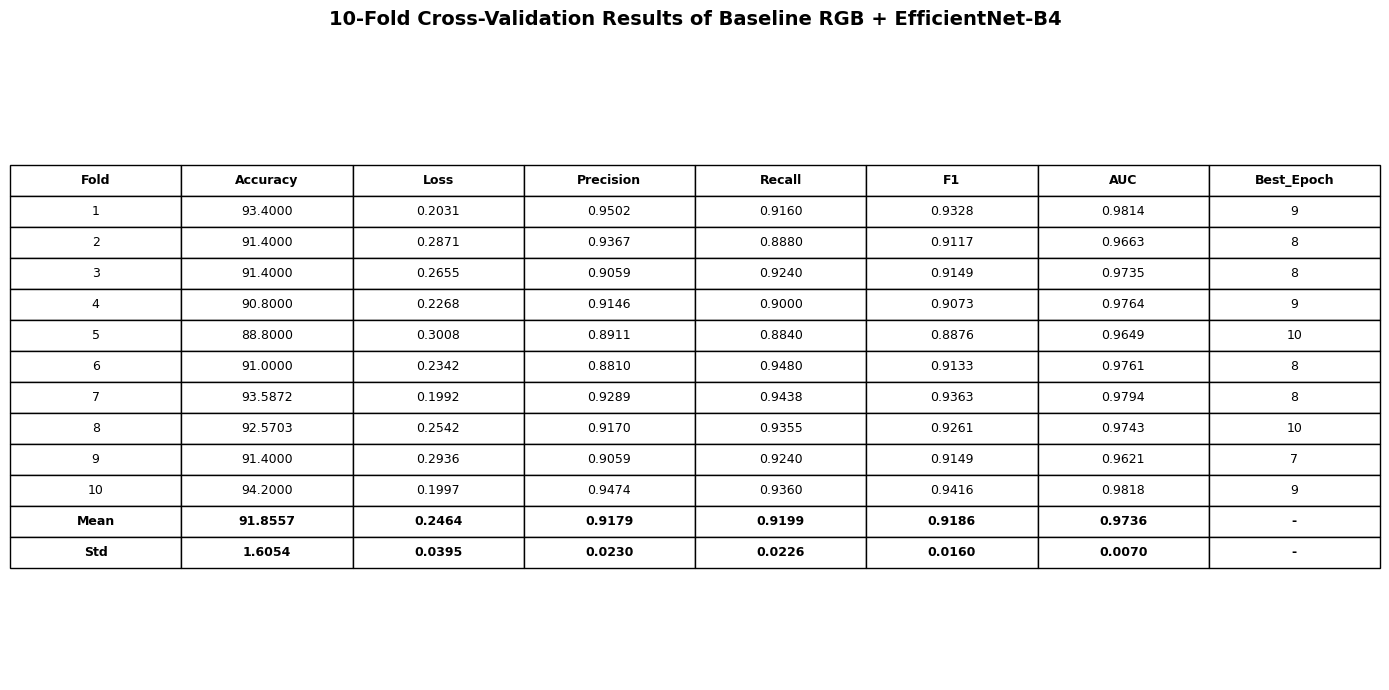


FILES SAVED:


/kaggle/working/baseline_10fold_results_table.png

/kaggle/working/baseline_10fold_mean_std.csv

In [17]:
# ============================================================
# CELL 14 : BASELINE 10-FOLD RESULTS
# TABLE + MEAN + STD + PNG + CSV
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. CREATE DATAFRAME
# ------------------------------------------------------------

baseline_results_df = pd.DataFrame(fold_results)

# ------------------------------------------------------------
# 2. CALCULATE MEAN
# ------------------------------------------------------------

mean_row = {
    "Fold": "Mean",
    "Accuracy": baseline_results_df["Accuracy"].mean(),
    "Loss": baseline_results_df["Loss"].mean(),
    "Precision": baseline_results_df["Precision"].mean(),
    "Recall": baseline_results_df["Recall"].mean(),
    "F1": baseline_results_df["F1"].mean(),
    "AUC": baseline_results_df["AUC"].mean(),
    "Best_Epoch": np.nan
}

# ------------------------------------------------------------
# 3. CALCULATE STANDARD DEVIATION
# ------------------------------------------------------------

std_row = {
    "Fold": "Std",
    "Accuracy": baseline_results_df["Accuracy"].std(ddof=1),
    "Loss": baseline_results_df["Loss"].std(ddof=1),
    "Precision": baseline_results_df["Precision"].std(ddof=1),
    "Recall": baseline_results_df["Recall"].std(ddof=1),
    "F1": baseline_results_df["F1"].std(ddof=1),
    "AUC": baseline_results_df["AUC"].std(ddof=1),
    "Best_Epoch": np.nan
}

# ------------------------------------------------------------
# 4. FINAL TABLE
# ------------------------------------------------------------

final_baseline_table = pd.concat(
    [
        baseline_results_df,
        pd.DataFrame([mean_row, std_row])
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 5. DISPLAY COPY
# ------------------------------------------------------------

display_table = final_baseline_table.copy()

for col in [
    "Accuracy",
    "Loss",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]:
    display_table[col] = display_table[col].apply(
        lambda x: f"{x:.4f}"
    )

display_table["Best_Epoch"] = display_table[
    "Best_Epoch"
].apply(
    lambda x: "-" if pd.isna(x) else str(int(x))
)

print("=" * 90)
print("BASELINE RGB + EfficientNet-B4 — 10-FOLD RESULTS")
print("=" * 90)

display(display_table)

# ------------------------------------------------------------
# 6. COMPLETE SUMMARY
# ------------------------------------------------------------

mean_acc = baseline_results_df["Accuracy"].mean()
std_acc = baseline_results_df["Accuracy"].std(ddof=1)

mean_precision = baseline_results_df["Precision"].mean()
std_precision = baseline_results_df["Precision"].std(ddof=1)

mean_recall = baseline_results_df["Recall"].mean()
std_recall = baseline_results_df["Recall"].std(ddof=1)

mean_f1 = baseline_results_df["F1"].mean()
std_f1 = baseline_results_df["F1"].std(ddof=1)

mean_auc = baseline_results_df["AUC"].mean()
std_auc = baseline_results_df["AUC"].std(ddof=1)

mean_loss = baseline_results_df["Loss"].mean()
std_loss = baseline_results_df["Loss"].std(ddof=1)

print("\n" + "=" * 70)
print("BASELINE FINAL PERFORMANCE SUMMARY")
print("=" * 70)

print(
    f"Accuracy  : {mean_acc:.2f} ± {std_acc:.2f}%"
)

print(
    f"Precision : {mean_precision:.4f} ± {std_precision:.4f}"
)

print(
    f"Recall    : {mean_recall:.4f} ± {std_recall:.4f}"
)

print(
    f"F1 Score  : {mean_f1:.4f} ± {std_f1:.4f}"
)

print(
    f"AUC       : {mean_auc:.4f} ± {std_auc:.4f}"
)

print(
    f"Loss      : {mean_loss:.4f} ± {std_loss:.4f}"
)

print("=" * 70)

# ------------------------------------------------------------
# 7. SAVE CSV
# ------------------------------------------------------------

final_baseline_table.to_csv(
    "baseline_10fold_mean_std.csv",
    index=False
)

# ------------------------------------------------------------
# 8. SAVE TABLE AS PAPER-QUALITY PNG
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 7)
)

ax.axis("off")

table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)

table.scale(
    1,
    1.6
)

# Bold header + Mean + Std
total_rows = len(display_table)

for (row, col), cell in table.get_celld().items():

    if row == 0:
        cell.set_text_props(
            weight="bold"
        )

    if row in [
        total_rows - 1,
        total_rows
    ]:
        cell.set_text_props(
            weight="bold"
        )

plt.title(
    "10-Fold Cross-Validation Results of Baseline RGB + EfficientNet-B4",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "baseline_10fold_results_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. DOWNLOAD LINKS
# ------------------------------------------------------------

print("\nFILES SAVED:")

display(
    FileLink(
        "baseline_10fold_results_table.png"
    )
)

display(
    FileLink(
        "baseline_10fold_mean_std.csv"
    )
)

BASELINE COMBINED 10-FOLD EVALUATION
Total samples       : 4997
Total predictions   : 4997
Total probabilities : 4997
Real samples        : 2500
Fake samples        : 2497

OVERALL BASELINE PERFORMANCE
Accuracy          : 91.86%
Precision         : 0.9173
Recall            : 0.9199
F1 Score          : 0.9186
ROC-AUC           : 0.9735
Average Precision : 0.9748

Confusion Matrix:
[[2293  207]
 [ 200 2297]]


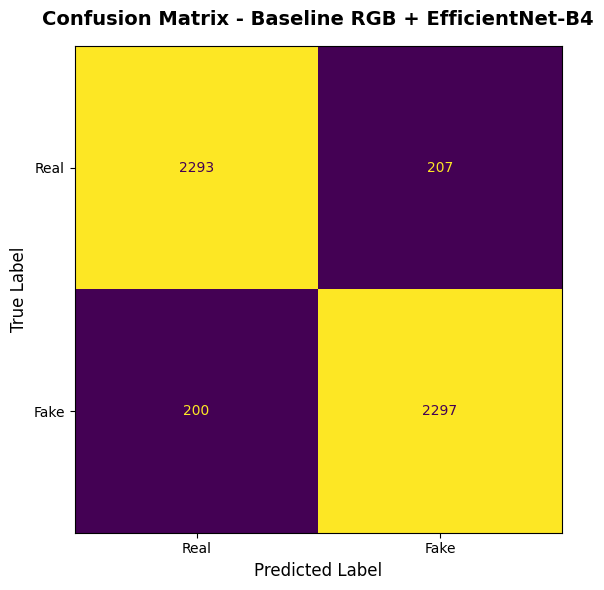

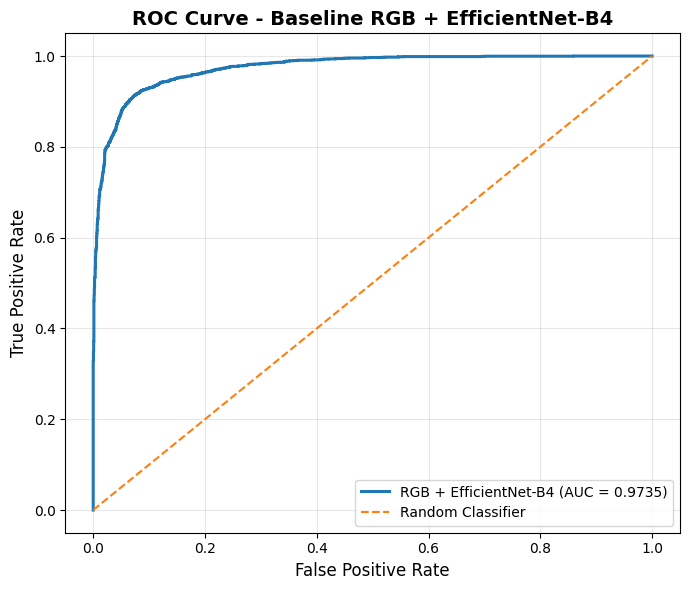

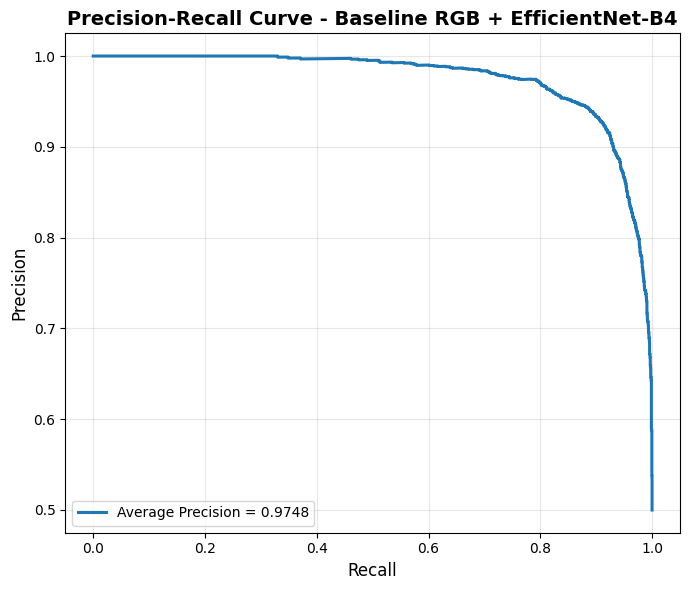

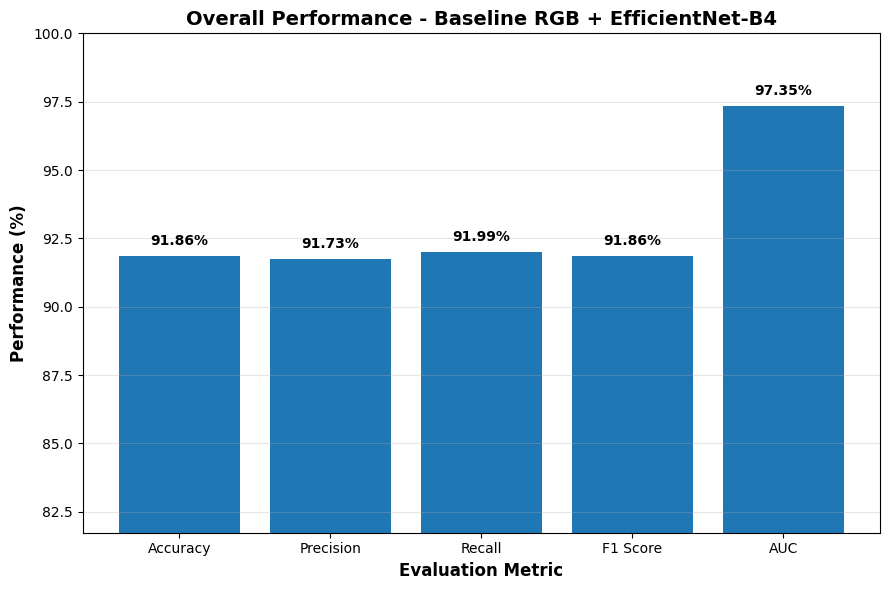


BASELINE OVERALL METRICS TABLE


,Metric,Value
0,Accuracy (%),91.8551
1,Precision,0.9173
2,Recall,0.9199
3,F1 Score,0.9186
4,ROC-AUC,0.9735
5,Average Precision,0.9748



BASELINE FIGURES SAVED SUCCESSFULLY
✓ baseline_confusion_matrix.png


/kaggle/working/baseline_confusion_matrix.png

✓ baseline_roc_curve.png


...

/kaggle/working/baseline_precision_recall_curve.png

✓ baseline_metrics_bar_chart.png


/kaggle/working/baseline_metrics_bar_chart.png

✓ baseline_overall_metrics.csv


/kaggle/working/baseline_overall_metrics.csv

In [18]:
# ============================================================
# CELL 15 : BASELINE PAPER-READY FIGURES
# 1. Confusion Matrix
# 2. ROC Curve + AUC
# 3. Precision-Recall Curve
# 4. Overall Metrics Bar Chart
# 5. Overall Metrics CSV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from IPython.display import display, FileLink


# ============================================================
# 1. SAFETY CHECK
# ============================================================

assert "all_folds_y_true" in globals(), \
    "all_folds_y_true not found. Complete Cell 13 first."

assert "all_folds_y_pred" in globals(), \
    "all_folds_y_pred not found. Complete Cell 13 first."

assert "all_folds_y_prob" in globals(), \
    "all_folds_y_prob not found. Complete Cell 13 first."


y_true = np.asarray(all_folds_y_true)
y_pred = np.asarray(all_folds_y_pred)
y_prob = np.asarray(all_folds_y_prob)


print("=" * 70)
print("BASELINE COMBINED 10-FOLD EVALUATION")
print("=" * 70)

print("Total samples       :", len(y_true))
print("Total predictions   :", len(y_pred))
print("Total probabilities :", len(y_prob))

print("Real samples        :", np.sum(y_true == 0))
print("Fake samples        :", np.sum(y_true == 1))


# ============================================================
# 2. OVERALL METRICS
# ============================================================

overall_accuracy = accuracy_score(
    y_true,
    y_pred
)

overall_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

overall_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

overall_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

overall_auc = roc_auc_score(
    y_true,
    y_prob
)

average_precision = average_precision_score(
    y_true,
    y_prob
)


print("\n" + "=" * 70)
print("OVERALL BASELINE PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy          : {overall_accuracy*100:.2f}%"
)

print(
    f"Precision         : {overall_precision:.4f}"
)

print(
    f"Recall            : {overall_recall:.4f}"
)

print(
    f"F1 Score          : {overall_f1:.4f}"
)

print(
    f"ROC-AUC           : {overall_auc:.4f}"
)

print(
    f"Average Precision : {average_precision:.4f}"
)

print("=" * 70)


# ============================================================
# 3. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Confusion Matrix - Baseline RGB + EfficientNet-B4",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Predicted Label",
    fontsize=12
)

ax.set_ylabel(
    "True Label",
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    "baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. ROC CURVE + AUC
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    linewidth=2.2,
    label=(
        f"RGB + EfficientNet-B4 "
        f"(AUC = {overall_auc:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curve - Baseline RGB + EfficientNet-B4",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "baseline_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. PRECISION-RECALL CURVE
# ============================================================

pr_precision, pr_recall, pr_thresholds = \
    precision_recall_curve(
        y_true,
        y_prob
    )

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    pr_recall,
    pr_precision,
    linewidth=2.2,
    label=(
        f"Average Precision = "
        f"{average_precision:.4f}"
    )
)

plt.xlabel(
    "Recall",
    fontsize=12
)

plt.ylabel(
    "Precision",
    fontsize=12
)

plt.title(
    "Precision-Recall Curve - Baseline RGB + EfficientNet-B4",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    loc="lower left"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "baseline_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. OVERALL METRICS BAR CHART
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]

metric_values = [
    overall_accuracy * 100,
    overall_precision * 100,
    overall_recall * 100,
    overall_f1 * 100,
    overall_auc * 100
]

plt.figure(
    figsize=(9, 6)
)

bars = plt.bar(
    metric_names,
    metric_values
)

# Add values above bars
for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.4,
        f"{value:.2f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.ylabel(
    "Performance (%)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Overall Performance - Baseline RGB + EfficientNet-B4",
    fontsize=14,
    fontweight="bold"
)

# Dynamic range
lower_limit = max(
    0,
    min(metric_values) - 10
)

upper_limit = min(
    100,
    max(metric_values) + 5
)

# Safety if upper and lower become same
if upper_limit <= lower_limit:
    lower_limit = 0
    upper_limit = 100

plt.ylim(
    lower_limit,
    upper_limit
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "baseline_metrics_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. SAVE OVERALL METRICS TABLE
# ============================================================

baseline_overall_metrics = pd.DataFrame({

    "Metric": [
        "Accuracy (%)",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision"
    ],

    "Value": [
        overall_accuracy * 100,
        overall_precision,
        overall_recall,
        overall_f1,
        overall_auc,
        average_precision
    ]
})

print("\nBASELINE OVERALL METRICS TABLE")

display(
    baseline_overall_metrics.round(4)
)

baseline_overall_metrics.to_csv(
    "baseline_overall_metrics.csv",
    index=False
)


# ============================================================
# 8. DOWNLOAD LINKS
# ============================================================

print("\n" + "=" * 70)
print("BASELINE FIGURES SAVED SUCCESSFULLY")
print("=" * 70)

files_to_download = [

    "baseline_confusion_matrix.png",

    "baseline_roc_curve.png",

    "baseline_precision_recall_curve.png",

    "baseline_metrics_bar_chart.png",

    "baseline_overall_metrics.csv"
]

for file_name in files_to_download:

    print("✓", file_name)

    display(
        FileLink(file_name)
    )

print("=" * 70)